# Feature Engineering
This notebook turns `cleaned_movies.csv` into model-ready features. Every feature uses only information available before a movie's release, because the project question asks whether success can be predicted before release. Features that look back in time use only earlier films. Imputation, encoding, and scaling are not done here, because they learn from the data and must be fit on the training set after the chronological split.

In [1]:
# Packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# One color for all single-series charts
BLUE = "#2a78d6"

### Step 1 Load the cleaned data
The cleaned data has one row per movie, 6,919 movies in total, with the target `success`. The first rows, `.info()`, and `.describe()` show the starting point before any features are added.

In [2]:
# Step 1: Load the cleaned data (one row per movie, with the target `success`)
movies = pd.read_csv(
    "../data/cleaned_movies.csv",
    dtype={"imdb_id": "string", "imdb_director_ids": "string", "collection_id": "Int64", "startYear": "Int64"},
    parse_dates=["release_date"],
)
print("Movies:", len(movies), "| Columns:", len(movies.columns))
movies.head()

Movies: 6919 | Columns: 28


,tmdb_id,imdb_id,title_tmdb,release_date,budget,revenue,runtime,genres,original_language,popularity,...,title_imdb,startYear,imdb_director_ids,imdb_directors,imdb_director_count,release_year,release_month,is_sequel,revenue_to_budget,success
0,11060,tt0099850,Internal Affairs,1990-01-12,15000000,27734391,115.0,Crime|Drama,en,3.7044,...,Internal Affairs,1990,nm0001214,Mike Figgis,1,1990,1,0,1.848959,0
1,25018,tt0099994,Leatherface: The Texas Chainsaw Massacre III,1990-01-12,2000000,5765562,81.0,Horror|Thriller,en,4.7092,...,Leatherface: Texas Chainsaw Massacre III,1990,nm0123009,Jeff Burr,1,1990,1,0,2.882781,1
2,9362,tt0100814,Tremors,1990-01-19,11000000,48572000,96.0,Comedy|Horror|Science Fiction,en,12.5504,...,Tremors,1990,nm0881038,Ron Underwood,1,1990,1,0,4.415636,1
3,16094,tt0099800,House Party,1990-01-20,2500000,26385628,104.0,Comedy,en,7.4720,...,House Party,1990,nm0399737,Reginald Hudlin,1,1990,1,0,10.554251,1
4,19384,tt0099817,Dark Angel,1990-01-26,7000000,9200000,91.0,Action|Thriller|Science Fiction|Horror,en,5.6382,...,I Come in Peace,1990,nm0062644,Craig R. Baxley,1,1990,1,0,1.314286,0


In [3]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 6919 entries, 0 to 6918
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   tmdb_id               6919 non-null   int64         
 1   imdb_id               6919 non-null   string        
 2   title_tmdb            6919 non-null   str           
 3   release_date          6919 non-null   datetime64[us]
 4   budget                6919 non-null   int64         
 5   revenue               6919 non-null   int64         
 6   runtime               6916 non-null   float64       
 7   genres                6919 non-null   str           
 8   original_language     6919 non-null   str           
 9   popularity            6919 non-null   float64       
 10  production_companies  6915 non-null   str           
 11  director_tmdb         6919 non-null   str           
 12  top_cast              6918 non-null   str           
 13  vote_count            6919 no

In [4]:
movies.describe().round(2)

,tmdb_id,release_date,budget,revenue,runtime,popularity,vote_count,vote_average,collection_id,startYear,imdb_director_count,release_year,release_month,is_sequel,revenue_to_budget,success
count,6919.00,6919,6.919000e+03,6.919000e+03,6916.00,6919.00,6919.00,6919.00,1711.0,6919.0,6919.00,6919.00,6919.00,6919.00,6919.00,6919.00
mean,194876.19,2009-03-11 08:43:38.181818,3.523952e+07,9.588831e+07,109.55,7.95,2595.67,6.50,383960.84,2008.61,1.10,2008.65,6.99,0.11,3.08,0.36
min,5.00,1990-01-12 00:00:00,2.500000e+05,1.215000e+03,63.00,0.12,100.00,2.00,10.0,1990.0,1.00,1990.00,1.00,0.00,0.00,0.00
25%,10169.50,2002-02-25 12:00:00,8.145000e+06,7.454042e+06,96.00,3.72,431.50,6.00,70068.0,2002.0,1.00,2002.00,4.00,0.00,0.61,0.00
50%,31203.00,2009-07-30 00:00:00,2.000000e+07,2.966717e+07,106.00,5.68,1124.00,6.50,180546.0,2009.0,1.00,2009.00,7.00,0.00,1.66,0.00
75%,315750.50,2016-06-25 12:00:00,4.200000e+07,9.926496e+07,119.00,9.28,2933.50,7.00,543738.0,2016.0,1.00,2016.00,10.00,0.00,3.47,1.00
max,1500536.00,2025-12-25 00:00:00,6.588000e+08,2.942178e+09,254.00,113.47,41669.00,8.80,1799800.0,2025.0,21.00,2025.00,12.00,1.00,125.00,1.00
std,292522.81,NaN,4.486272e+07,1.896943e+08,19.79,7.41,3990.09,0.78,441097.1,9.28,0.47,9.30,3.42,0.32,5.65,0.48


### Step 2 Load the reference tables for history features
History features need more films than the cleaned set. `combined_dataset.csv` holds all 13,276 matched movies, including those without budget data, which still count as earlier films for actors, companies, and franchises. `imdb_movies.csv` holds every IMDb movie with its directors, which gives each director's full career, not only the years in our data.

In [5]:
# Load the two reference tables used for history features
# All matched TMDB movies (13,276), including those without budget data, for counting earlier films
all_movies = pd.read_csv("../data/combined_dataset.csv", parse_dates=["release_date"])
all_movies = all_movies.drop_duplicates(subset="tmdb_id")
all_movies["release_year"] = all_movies["release_date"].dt.year

# Every IMDb movie with its directors, for counting each director's full career
imdb = pd.read_csv("../data/imdb_movies.csv", dtype={"imdb_id": "string", "nconst": "string", "startYear": "Int64"})
imdb = imdb.dropna(subset=["startYear"])   # a film without a year cannot be placed before or after another

print("All matched TMDB movies:", len(all_movies))
print("IMDb movie-director rows with a year:", len(imdb))

All matched TMDB movies: 13276
IMDb movie-director rows with a year: 692953


### Step 3 Log of budget
Budget is strongly right-skewed, with a few very expensive movies far from the rest. Taking the log spreads the values out so that these movies do not dominate distance-based models such as KNN or the coefficients of logistic regression. The two histograms and the skewness values show the change.

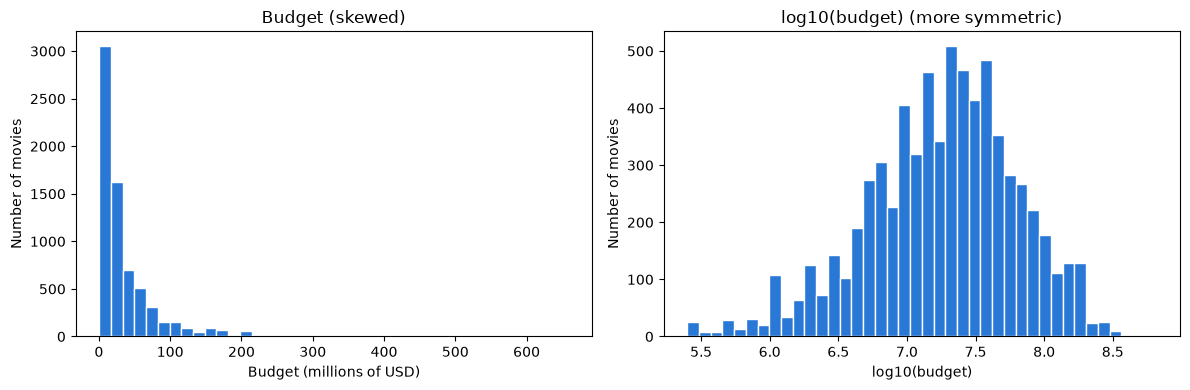

Skewness of budget: 3.06
Skewness of log10(budget): -0.46


In [6]:
#  Log of budget
# Budget is heavily right-skewed. the log spreads it out so a few blockbusters do not dominate
movies["log_budget"] = np.log10(movies["budget"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(movies["budget"] / 1_000_000, bins=40, color=BLUE, edgecolor="white")
axes[0].set_xlabel("Budget (millions of USD)")
axes[0].set_ylabel("Number of movies")
axes[0].set_title("Budget (skewed)")
axes[1].hist(movies["log_budget"], bins=40, color=BLUE, edgecolor="white")
axes[1].set_xlabel("log10(budget)")
axes[1].set_ylabel("Number of movies")
axes[1].set_title("log10(budget) (more symmetric)")
plt.tight_layout()
plt.show()

print("Skewness of budget:", round(movies["budget"].skew(), 2))
print("Skewness of log10(budget):", round(movies["log_budget"].skew(), 2))

### Step 4 Genre flags
A movie can have several genres in one `|` separated text field, which models cannot use directly. Each genre becomes its own 0/1 column, so a movie that is both Action and Comedy gets a 1 in both. The bar chart shows how often each genre appears. "TV Movie" appears only 3 times, which is too few to learn from, so it gets no column. `n_genres` counts how many genres a movie lists.

genres
Drama              3231
Comedy             2533
Thriller           1883
Action             1747
Adventure          1231
Crime              1189
Romance            1178
Horror              893
Science Fiction     783
Family              772
Fantasy             769
Mystery             602
Animation           448
History             385
War                 219
Music               199
Western              81
Documentary          47
TV Movie              3
Name: count, dtype: int64


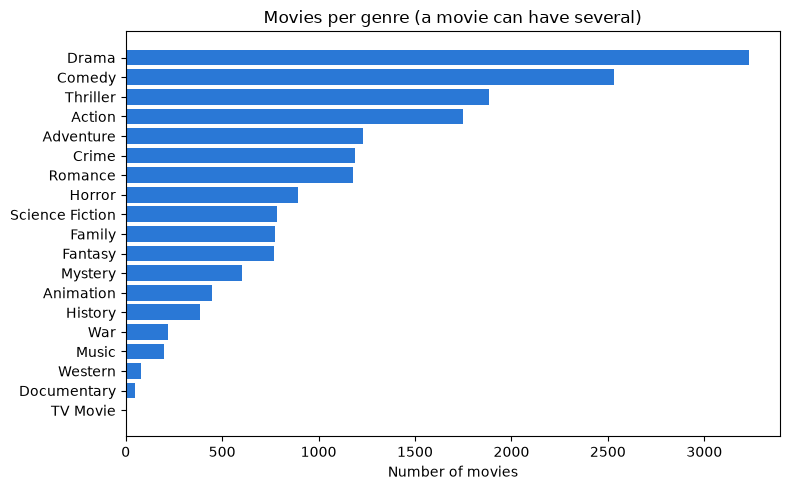

In [7]:
#  Genre flags
# genres is a "|" list, and a movie can have several, so each genre gets its own 0/1 column
genre_counts = movies["genres"].str.split("|").explode().value_counts()
print(genre_counts)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(genre_counts.index[::-1], genre_counts.values[::-1], color=BLUE)
ax.set_xlabel("Number of movies")
ax.set_title("Movies per genre (a movie can have several)")
plt.tight_layout()
plt.show()

In [8]:
# "TV Movie" has only 3 movies, too few to learn from, so it gets no flag
genre_list = []
for genre in genre_counts.index:
    if genre != "TV Movie":
        genre_list.append(genre)

genre_columns = []
for genre in genre_list:
    column = "genre_" + genre.lower().replace(" ", "_")          # e.g. "Science Fiction" -> genre_science_fiction
    movies[column] = movies["genres"].str.split("|").apply(lambda names: int(genre in names))
    genre_columns.append(column)

# Number of genres listed for each movie
movies["n_genres"] = movies["genres"].str.split("|").apply(len)

print("Genre flags created:", len(genre_columns))
movies[["title_tmdb", "genres", "n_genres"] + genre_columns[:5]].head()

Genre flags created: 18


,title_tmdb,genres,n_genres,genre_drama,genre_comedy,genre_thriller,genre_action,genre_adventure
0,Internal Affairs,Crime|Drama,2,1,0,0,0,0
1,Leatherface: The Texas Chainsaw Massacre III,Horror|Thriller,2,0,0,1,0,0
2,Tremors,Comedy|Horror|Science Fiction,3,0,1,0,0,0
3,House Party,Comedy,1,0,1,0,0,0
4,Dark Angel,Action|Thriller|Science Fiction|Horror,4,0,0,1,1,0


### Step 5 English-language flag
Most movies are in English and the rest are spread across many languages, many with only a few movies each. A single 0/1 flag captures the main difference without creating dozens of rare categories.

In [9]:
#  English-language flag
# 84% of movies are in English and the rest are spread across many languages,
# so a single 0/1 flag captures the main difference without dozens of rare categories
movies["is_english"] = (movies["original_language"] == "en").astype(int)
print(movies["is_english"].value_counts())

is_english
1    5825
0    1094
Name: count, dtype: int64


### Step 6 Director experience from IMDb
A director's track record is known before release and may signal the chance of success. Using the IMDb director IDs, this step counts how many feature films the movie's directors made before this movie, and how many years have passed since their first one. Only films from earlier IMDb years count, and IMDb years are compared only with IMDb years. Because IMDb covers each director's full career, these counts are not limited by our data starting in 1990. Directors with no earlier film are flagged as first-time directors.

In [10]:
# Director career length from IMDb (all of a director's earlier films, not just those in our data)
# Rule: only films from EARLIER IMDb years count (IMDb years are compared only with IMDb years)

# Build a lookup: director ID -> list of (year, imdb_id) for every IMDb movie they directed
director_career = {}
for director_id, film_id, year in zip(imdb["nconst"], imdb["imdb_id"], imdb["startYear"]):
    if director_id not in director_career:
        director_career[director_id] = []
    director_career[director_id].append((year, film_id))

def director_history_imdb(director_ids, this_year):
    """Count distinct earlier films by any of the movie's directors, and years since their first film."""
    earlier_films = set()
    first_year = None
    for director_id in director_ids.split("|"):
        for year, film_id in director_career.get(director_id, []):
            if year < this_year:
                earlier_films.add(film_id)
                if first_year is None or year < first_year:
                    first_year = year
    if first_year is None:
        return 0, 0
    return len(earlier_films), this_year - first_year

prior_films = []
years_active = []
for director_ids, this_year in zip(movies["imdb_director_ids"], movies["startYear"]):
    count, years = director_history_imdb(director_ids, this_year)
    prior_films.append(count)
    years_active.append(years)

movies["dir_prior_films"] = prior_films          # earlier feature films directed (IMDb)
movies["dir_years_active"] = years_active        # years since the director's first feature film
movies["dir_first_film"] = (movies["dir_prior_films"] == 0).astype(int)   # first-time director flag

print(movies[["dir_prior_films", "dir_years_active"]].describe().round(1))
print("First-time directors:", movies["dir_first_film"].sum())

       dir_prior_films  dir_years_active
count           6919.0            6919.0
mean               5.6              12.6
std                7.7              11.0
min                0.0               0.0
25%                1.0               4.0
50%                3.0              10.0
75%                7.0              19.0
max              168.0              65.0
First-time directors: 1074


### Step 7 Director track record in our data
This step measures how a director's earlier films performed at the box office, using films in our cleaned data whose outcome is known. Only films from earlier TMDB release years count, so their final box office was already known when the new movie was released. A film co-directed by two directors is counted once. When a director has no earlier film in our data, the success rate is left missing and `dir_no_track_record` is set to 1, so the model can tell "no record" apart from "a record of 0%". The missing rates are filled later inside the model pipeline using training data only.

In [11]:
#  Director track record inside our data (box-office outcomes of their earlier films)
# Rule: only films from EARLIER TMDB release years count, so their final box office was known
director_outcomes = {}
for director_ids, film_id, year, success in zip(movies["imdb_director_ids"], movies["tmdb_id"], movies["release_year"], movies["success"]):
    for director_id in director_ids.split("|"):
        if director_id not in director_outcomes:
            director_outcomes[director_id] = []
        director_outcomes[director_id].append((year, film_id, success))

def director_track_record(director_ids, this_year):
    """Number of earlier films with known outcomes, and their success rate (None if there are none)."""
    earlier = {}
    for director_id in director_ids.split("|"):
        for year, film_id, success in director_outcomes.get(director_id, []):
            if year < this_year:
                earlier[film_id] = success          # dictionary keeps each film once for co-directors
    if len(earlier) == 0:
        return 0, np.nan
    return len(earlier), sum(earlier.values()) / len(earlier)

known_films = []
success_rates = []
for director_ids, this_year in zip(movies["imdb_director_ids"], movies["release_year"]):
    count, rate = director_track_record(director_ids, this_year)
    known_films.append(count)
    success_rates.append(rate)

movies["dir_prior_known_films"] = known_films         # earlier films in our data with a known outcome
movies["dir_prior_success_rate"] = success_rates      # missing when there is no earlier record
movies["dir_no_track_record"] = (movies["dir_prior_known_films"] == 0).astype(int)

print("Directors with no earlier record in our data:", movies["dir_no_track_record"].sum())
print(movies["dir_prior_success_rate"].describe().round(3))

Directors with no earlier record in our data: 2830
count    4089.000
mean        0.461
std         0.379
min         0.000
25%         0.000
50%         0.500
75%         0.800
max         1.000
Name: dir_prior_success_rate, dtype: float64


The table below checks the history features on the movies with the longest records. The counts and rates look reasonable. Anthology films with many directors, such as "Paris, je t'aime", combine the records of all their directors.

In [12]:
# Look at a few well-known directors to check the history features make sense
director_columns = ["title_tmdb", "release_year", "imdb_directors", "dir_prior_films", "dir_years_active",
                    "dir_prior_known_films", "dir_prior_success_rate"]
movies.sort_values("dir_prior_known_films", ascending=False)[director_columns].head()

,title_tmdb,release_year,imdb_directors,dir_prior_films,dir_years_active,dir_prior_known_films,dir_prior_success_rate
2644,Paris Je T'aime,2006,Olivier Assayas|Frédéric Auburtin|Gurinder Cha...,112,34,45,0.422222
4342,Movie 43,2013,Elizabeth Banks|Steven Brill|Steve Carr|Rusty ...,49,20,36,0.361111
6494,Coup de chance,2023,Woody Allen,50,57,27,0.259259
6705,Juror #2,2024,Clint Eastwood,41,53,26,0.384615
5871,A Rainy Day in New York,2019,Woody Allen,48,53,26,0.269231


The left histogram shows that most movies have directors with only a few earlier films. The right histogram shows that track-record rates cluster at 0 and 1, because a director with only one or two earlier films can only score 0%, 50%, or 100%. This is why `dir_prior_known_films` is kept next to the rate, so a model can weigh a rate based on many films more than one based on a single film.

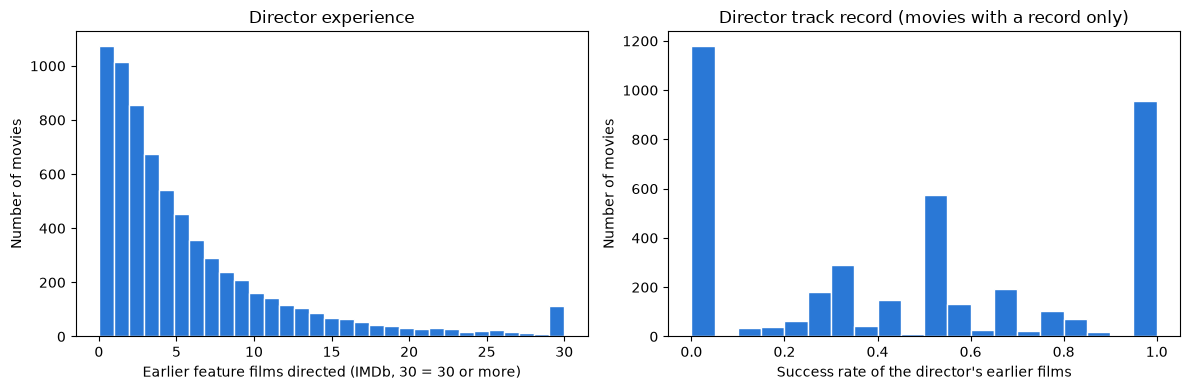

In [13]:
# Distribution of director experience
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(movies["dir_prior_films"].clip(upper=30), bins=31, color=BLUE, edgecolor="white")
axes[0].set_xlabel("Earlier feature films directed (IMDb, 30 = 30 or more)")
axes[0].set_ylabel("Number of movies")
axes[0].set_title("Director experience")
axes[1].hist(movies["dir_prior_success_rate"].dropna(), bins=20, color=BLUE, edgecolor="white")
axes[1].set_xlabel("Success rate of the director's earlier films")
axes[1].set_ylabel("Number of movies")
axes[1].set_title("Director track record (movies with a record only)")
plt.tight_layout()
plt.show()

### Step 8 Lead actor experience in the previous 5 years
Star power is known before release. TMDB lists cast names without IDs, so the first-billed actor is matched by name, which can occasionally merge two actors with the same name. The count includes only films from the 5 years before the movie's release year. A fixed window is used because our data starts in 1990, so counting all earlier films would make the count grow with the release year simply because more earlier years are available.

In [14]:
#  Lead actor experience in the previous 5 years
# TMDB gives cast names only (no IDs), so the first-billed actor is matched by name.
# Counts films from the 5 years before this movie's year, in all 13,276 matched movies,
# where that actor is in the top 5 billed cast. A fixed 5-year window keeps the count
# comparable across years, because our data only starts in 1990.
HISTORY_YEARS = 5

actor_years = {}
for cast, year in zip(all_movies["top_cast"].fillna(""), all_movies["release_year"]):
    for name in cast.split("|"):
        if name != "":
            if name not in actor_years:
                actor_years[name] = []
            actor_years[name].append(year)

lead_recent = []
for cast, this_year in zip(movies["top_cast"].fillna(""), movies["release_year"]):
    lead = cast.split("|")[0]
    count = 0
    for year in actor_years.get(lead, []):
        if this_year - HISTORY_YEARS <= year < this_year:
            count += 1
    lead_recent.append(count)

movies["lead_actor_films_5yr"] = lead_recent
print(movies["lead_actor_films_5yr"].describe().round(1))

count    6919.0
mean        3.9
std         3.3
min         0.0
25%         1.0
50%         3.0
75%         6.0
max        20.0
Name: lead_actor_films_5yr, dtype: float64


### Step 9 Production company activity in the previous 5 years
Larger and more active studios may have bigger marketing and distribution reach. Instead of hand-picking a list of major studios, this step counts how many films each of the movie's production companies released in the previous 5 years and keeps the largest count. The same 5-year window keeps the feature comparable across years.

In [15]:
#  Production company activity in the previous 5 years
# The largest number of films, from the 5 years before this movie's year, made by any of the
# movie's production companies. This measures studio size and activity without hand-picking
# a list of "major" studios.
company_years = {}
for companies, year in zip(all_movies["production_companies"].fillna(""), all_movies["release_year"]):
    for company in companies.split("|"):
        if company != "":
            if company not in company_years:
                company_years[company] = []
            company_years[company].append(year)

company_recent = []
for companies, this_year in zip(movies["production_companies"].fillna(""), movies["release_year"]):
    best = 0
    for company in companies.split("|"):
        count = 0
        for year in company_years.get(company, []):
            if this_year - HISTORY_YEARS <= year < this_year:
                count += 1
        if count > best:
            best = count
    company_recent.append(best)

movies["company_films_5yr"] = company_recent
print(movies["company_films_5yr"].describe().round(1))

count    6919.0
mean       26.2
std        23.0
min         0.0
25%         5.0
50%        20.0
75%        45.0
max        91.0
Name: company_films_5yr, dtype: float64


### Step 10 Earlier films in the same franchise
`is_sequel` from the cleaning step says whether an earlier film in the collection exists. This step adds how many earlier films the franchise has, since a fourth installment may behave differently from a second. It uses TMDB release dates on both sides, and movies outside a collection get 0.

In [16]:
# Number of earlier films in the same franchise
# Uses TMDB release dates on both sides, like is_sequel; 0 for movies not in a collection
collection_dates = {}
for collection_id, date in zip(all_movies["collection_id"], all_movies["release_date"]):
    if pd.notna(collection_id):
        if collection_id not in collection_dates:
            collection_dates[collection_id] = []
        collection_dates[collection_id].append(date)

franchise_prior = []
for collection_id, this_date in zip(movies["collection_id"], movies["release_date"]):
    count = 0
    if pd.notna(collection_id):
        for date in collection_dates.get(collection_id, []):
            if date < this_date:
                count += 1
    franchise_prior.append(count)

movies["franchise_prior_films"] = franchise_prior
print(movies["franchise_prior_films"].value_counts().sort_index().head(8))
movies.loc[movies["franchise_prior_films"] > 0, ["title_tmdb", "release_year", "collection_name", "is_sequel", "franchise_prior_films"]].head()

franchise_prior_films
0    6142
1     466
2     172
3      68
4      32
5      16
6       8
7       6
Name: count, dtype: int64


,title_tmdb,release_year,collection_name,is_sequel,franchise_prior_films
114,Teenage Mutant Ninja Turtles II: The Secret of...,1991,Teenage Mutant Ninja Turtles Collection,1,1
143,Problem Child 2,1991,Problem Child Collection,1,1
166,Child's Play 3,1991,Child's Play Collection,1,1
186,House Party 2,1991,House Party Collection,1,1
247,Patriot Games,1992,The Jack Ryan Collection,1,1


The table below checks whether the history features grow with the release year, which would let a model confuse "later year" with "more experience". The IMDb director counts stay flat across periods, and the 5-year actor and company counts are flat from 1995 onward. Movies from 1990 to 1994 have lower values because there are fewer than 5 earlier years in our data. One option to decide at the split is to use 1990 to 1994 only as history and not as training rows. The in-data director track record also rises over time, which is another reason to rely on the rate together with the count.

In [17]:
# Check that history features do not simply grow with the release year
# Our data starts in 1990, so movies from 1990-1994 have little or no earlier history in the data
history_columns = ["dir_prior_films", "dir_prior_known_films", "dir_no_track_record",
                   "lead_actor_films_5yr", "company_films_5yr", "franchise_prior_films"]
period = pd.cut(movies["release_year"], bins=[1989, 1994, 1999, 2004, 2009, 2014, 2019, 2025],
                labels=["1990-94", "1995-99", "2000-04", "2005-09", "2010-14", "2015-19", "2020-25"])
movies.groupby(period, observed=True)[history_columns].mean().round(2)

,dir_prior_films,dir_prior_known_films,dir_no_track_record,lead_actor_films_5yr,company_films_5yr,franchise_prior_films
release_year,,,,,,
1990-94,6.37,0.38,0.71,1.65,12.68,0.05
1995-99,5.62,1.23,0.43,3.89,31.42,0.07
2000-04,5.46,1.76,0.41,3.99,28.87,0.14
2005-09,5.34,2.07,0.40,3.93,26.73,0.15
2010-14,5.40,2.58,0.37,4.48,27.66,0.24
2015-19,5.59,2.78,0.33,4.58,27.48,0.32
2020-25,5.96,2.84,0.38,3.28,23.42,0.34


### Step 11 Choose the model columns
The model table keeps ID columns for identifying movies and ordering the time split, the target, and only pre-release features. Revenue, the revenue to budget ratio, popularity, vote count, and vote average are left out, so they cannot be used as predictors by mistake. `us_certification` and `release_month` are categories that will be one-hot encoded after the split. The table has 12 numeric, 2 categorical, and 22 binary features, which meets the requirement of at least 4 numeric and 4 categorical variables.

In [18]:
# Choose the model columns
ID_COLUMNS = ["tmdb_id", "imdb_id", "title_tmdb", "release_date"]     # identify movies and order the time split
TARGET = "success"
NUMERIC_FEATURES = [
    "log_budget", "runtime", "release_year", "n_genres", "imdb_director_count",
    "dir_prior_films", "dir_years_active", "dir_prior_known_films", "dir_prior_success_rate",
    "lead_actor_films_5yr", "company_films_5yr", "franchise_prior_films",
]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]          # one-hot encoded later, after the split
BINARY_FEATURES = ["is_sequel", "is_english", "dir_first_film", "dir_no_track_record"] + genre_columns

model_data = movies[ID_COLUMNS + NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES + [TARGET]].copy()
print("Numeric:", len(NUMERIC_FEATURES), "| Categorical:", len(CATEGORICAL_FEATURES), "| Binary:", len(BINARY_FEATURES))
model_data.head()

Numeric: 12 | Categorical: 2 | Binary: 22


,tmdb_id,imdb_id,title_tmdb,release_date,log_budget,runtime,release_year,n_genres,imdb_director_count,dir_prior_films,...,genre_family,genre_fantasy,genre_mystery,genre_animation,genre_history,genre_war,genre_music,genre_western,genre_documentary,success
0,11060,tt0099850,Internal Affairs,1990-01-12,7.176091,115.0,1990,2,1,1,...,0,0,0,0,0,0,0,0,0,0
1,25018,tt0099994,Leatherface: The Texas Chainsaw Massacre III,1990-01-12,6.301030,81.0,1990,2,1,2,...,0,0,0,0,0,0,0,0,0,1
2,9362,tt0100814,Tremors,1990-01-19,7.041393,96.0,1990,3,1,0,...,0,0,0,0,0,0,0,0,0,1
3,16094,tt0099800,House Party,1990-01-20,6.397940,104.0,1990,1,1,0,...,0,0,0,0,0,0,0,0,0,1
4,19384,tt0099817,Dark Angel,1990-01-26,6.845098,91.0,1990,4,1,1,...,0,0,0,0,0,0,0,0,0,0


The heatmap shows how the numeric features relate to each other and to `success`. Director experience features are strongly correlated with each other, which matters for logistic regression and is a reason to try PCA or regularization later. No single numeric feature is strongly correlated with `success` on its own, so the models will need to combine several features. The values below the chart rank each feature's correlation with the target.

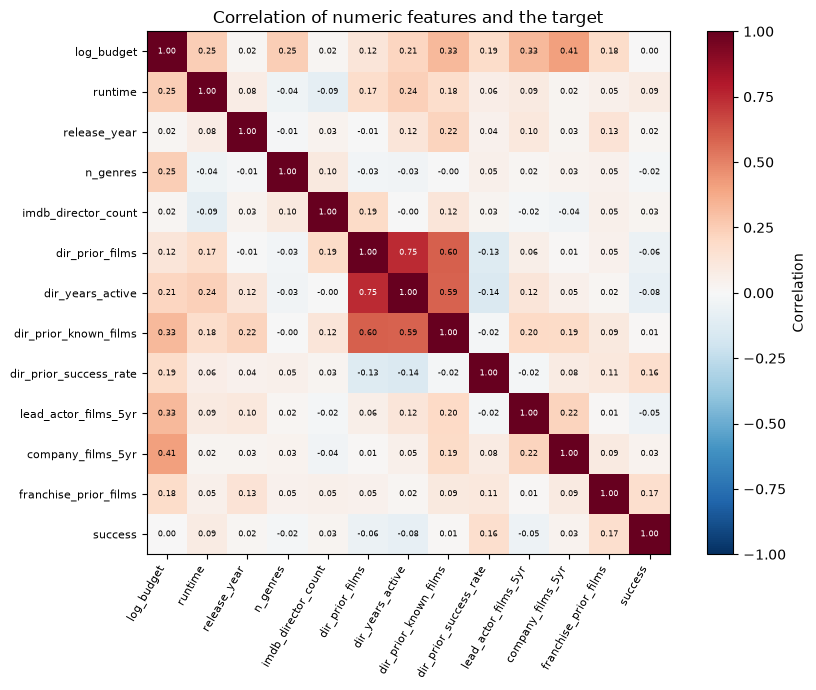

dir_years_active         -0.079
dir_prior_films          -0.057
lead_actor_films_5yr     -0.051
n_genres                 -0.023
log_budget                0.004
dir_prior_known_films     0.012
release_year              0.022
imdb_director_count       0.031
company_films_5yr         0.032
runtime                   0.085
dir_prior_success_rate    0.164
franchise_prior_films     0.168
Name: success, dtype: float64

In [19]:
# Correlation between numeric features and the target
# Strongly correlated features carry overlapping information, which matters for logistic regression and PCA
corr = model_data[NUMERIC_FEATURES + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr.columns)))
ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) > 0.6 else "black"     # readable on dark cells
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=6, color=text_color)
fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Correlation of numeric features and the target")
plt.tight_layout()
plt.show()

corr[TARGET].drop(TARGET).sort_values().round(3)

### Step 12 Final check
`.info()` and `.describe()` confirm the column types and ranges of the model table. The only missing values are the 3 unreported runtimes and the director success rate for movies without an earlier record. Both are filled later inside the model pipeline using training data only.

In [20]:
# Final check
model_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6919 entries, 0 to 6918
Data columns (total 41 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   tmdb_id                 6919 non-null   int64         
 1   imdb_id                 6919 non-null   string        
 2   title_tmdb              6919 non-null   str           
 3   release_date            6919 non-null   datetime64[us]
 4   log_budget              6919 non-null   float64       
 5   runtime                 6916 non-null   float64       
 6   release_year            6919 non-null   int64         
 7   n_genres                6919 non-null   int64         
 8   imdb_director_count     6919 non-null   int64         
 9   dir_prior_films         6919 non-null   int64         
 10  dir_years_active        6919 non-null   int64         
 11  dir_prior_known_films   6919 non-null   int64         
 12  dir_prior_success_rate  4089 non-null   float64       
 13 

In [21]:
model_data.describe().round(2)

,tmdb_id,release_date,log_budget,runtime,release_year,n_genres,imdb_director_count,dir_prior_films,dir_years_active,dir_prior_known_films,...,genre_family,genre_fantasy,genre_mystery,genre_animation,genre_history,genre_war,genre_music,genre_western,genre_documentary,success
count,6919.00,6919,6919.00,6916.00,6919.00,6919.00,6919.00,6919.00,6919.00,6919.00,...,6919.00,6919.00,6919.00,6919.00,6919.00,6919.00,6919.00,6919.00,6919.00,6919.00
mean,194876.19,2009-03-11 08:43:38.181818,7.25,109.55,2008.65,2.63,1.10,5.61,12.58,2.10,...,0.11,0.11,0.09,0.06,0.06,0.03,0.03,0.01,0.01,0.36
min,5.00,1990-01-12 00:00:00,5.40,63.00,1990.00,1.00,1.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,10169.50,2002-02-25 12:00:00,6.91,96.00,2002.00,2.00,1.00,1.00,4.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,31203.00,2009-07-30 00:00:00,7.30,106.00,2009.00,3.00,1.00,3.00,10.00,1.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,315750.50,2016-06-25 12:00:00,7.62,119.00,2016.00,3.00,1.00,7.00,19.00,3.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00
max,1500536.00,2025-12-25 00:00:00,8.82,254.00,2025.00,7.00,21.00,168.00,65.00,45.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
std,292522.81,NaN,0.55,19.79,9.30,0.99,0.47,7.74,10.99,3.21,...,0.31,0.31,0.28,0.25,0.23,0.18,0.17,0.11,0.08,0.48


In [22]:
# Missing values left on purpose; they are filled inside the model pipeline using training data only
missing = model_data.isna().sum()
print(missing[missing > 0])

runtime                      3
dir_prior_success_rate    2830
dtype: int64


### Step 13 Save the model-ready data

In [23]:
#  Save the model-ready data
model_data.to_csv("../data/model_data.csv", index=False)
print(f"Saved ../data/model_data.csv: {len(model_data):,} rows and {len(model_data.columns)} columns")

Saved ../data/model_data.csv: 6,919 rows and 41 columns
